In [2]:
import pandas as pd
import numpy as np
import os

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("D:\\Applications\\MLops-OList dataset\\sentinelml-network-intrusion-detection\\notebooks\\data\\raw\\rt_iot2022.csv")

print("Original dataset shape:", df.shape)

Original dataset shape: (123117, 84)


In [4]:
feature_columns = df.columns.drop("Attack_type")

conflicting_indices = df.groupby(
    list(feature_columns),
    dropna=False
)["Attack_type"].transform("nunique") > 1

df_model = df[~conflicting_indices].copy()

print("Modeling dataset shape:", df_model.shape)

Modeling dataset shape: (122989, 84)


In [5]:
normal_labels = [
    "MQTT_Publish",
    "Thing_Speak",
    "Wipro_bulb"
]

attack_labels = [
    "DOS_SYN_Hping",
    "ARP_poisioning",
    "NMAP_UDP_SCAN",
    "NMAP_XMAS_TREE_SCAN",
    "NMAP_OS_DETECTION",
    "NMAP_TCP_scan",
    "DDOS_Slowloris",
    "Metasploit_Brute_Force_SSH",
    "NMAP_FIN_SCAN"
]

df_model["Binary_target"] = (
    df_model["Attack_type"]
    .isin(attack_labels)
    .astype(int)
)

print(df_model["Binary_target"].value_counts())

Binary_target
1    110560
0     12429
Name: count, dtype: int64


In [6]:
manifest = pd.read_csv(
    "D:\\Applications\\MLops-OList dataset\\sentinelml-network-intrusion-detection\\notebooks\\data\\processed\\split_manifest.csv"
)

print(manifest.head())
print("\nSplit distribution:")
print(manifest["split"].value_counts())

   original_index  split
0               1  train
1               2  train
2               4  train
3               5  train
4               7  train

Split distribution:
split
train         78712
test          24598
validation    19679
Name: count, dtype: int64


In [7]:
# Separate input features and targets

X = df_model.drop(
    columns=[
        "Attack_type",
        "Binary_target",
        "bwd_URG_flag_count"
    ]
).copy()

y_binary = df_model["Binary_target"].copy()
y_multi = df_model["Attack_type"].copy()


# Extract positional indices from manifest

train_idx = manifest.loc[
    manifest["split"] == "train",
    "original_index"
].astype(int).to_numpy()

val_idx = manifest.loc[
    manifest["split"] == "validation",
    "original_index"
].astype(int).to_numpy()

test_idx = manifest.loc[
    manifest["split"] == "test",
    "original_index"
].astype(int).to_numpy()


# Reconstruct datasets using positional indexing

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_binary_train = y_binary.iloc[train_idx].copy()
y_binary_val = y_binary.iloc[val_idx].copy()
y_binary_test = y_binary.iloc[test_idx].copy()

y_multi_train = y_multi.iloc[train_idx].copy()
y_multi_val = y_multi.iloc[val_idx].copy()
y_multi_test = y_multi.iloc[test_idx].copy()


print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (78712, 82)
Validation: (19679, 82)
Testing: (24598, 82)


In [8]:
assert len(X_train) == 78712
assert len(X_val) == 19679
assert len(X_test) == 24598

assert len(X_train) + len(X_val) + len(X_test) == len(X)

assert set(train_idx).isdisjoint(set(val_idx))
assert set(train_idx).isdisjoint(set(test_idx))
assert set(val_idx).isdisjoint(set(test_idx))

print("All split reconstruction checks passed!")

All split reconstruction checks passed!


In [9]:
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 80
Categorical features: 2


In [10]:
numerical_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_scaled = ColumnTransformer([
    ("numerical", numerical_pipeline_scaled, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [11]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_binary_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [12]:
y_val_pred = logistic_model.predict(X_val)
y_val_prob = logistic_model.predict_proba(X_val)

In [13]:
accuracy = accuracy_score(y_binary_val, y_val_pred)

balanced_accuracy = balanced_accuracy_score(
    y_binary_val, y_val_pred
)

precision = precision_score(
    y_binary_val,
    y_val_pred,
    pos_label=1
)

recall = recall_score(
    y_binary_val,
    y_val_pred,
    pos_label=1
)

f1 = f1_score(
    y_binary_val,
    y_val_pred,
    pos_label=1
)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy,
        balanced_accuracy,
        precision,
        recall,
        f1
    ]
})

display(results)

,Metric,Score
0,Accuracy,0.972560
1,Balanced Accuracy,0.980945
2,Precision,0.999011
3,Recall,0.970434
4,F1 Score,0.984515


In [14]:
print(classification_report(
    y_binary_val,
    y_val_pred,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.79      0.99      0.88      1990
      Attack       1.00      0.97      0.98     17689

    accuracy                           0.97     19679
   macro avg       0.89      0.98      0.93     19679
weighted avg       0.98      0.97      0.97     19679



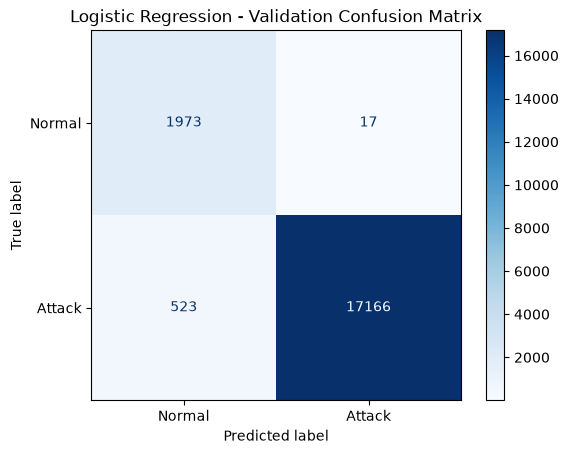

In [15]:
cm = confusion_matrix(
    y_binary_val,
    y_val_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()

In [16]:
model_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }
])

display(model_results)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.97256,0.980945,0.999011,0.970434,0.984515


In [17]:
os.makedirs("../reports/metrics", exist_ok=True)

model_results.to_csv(
    "../reports/metrics/binary_model_comparison.csv",
    index=False
)

In [18]:
from sklearn.tree import DecisionTreeClassifier

numerical_pipeline_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_tree = ColumnTransformer([
    ("numerical", numerical_pipeline_tree, numerical_features),
    ("categorical", categorical_pipeline_tree, categorical_features)
])

In [19]:
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor_tree),

    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

In [20]:
decision_tree_model.fit(
    X_train,
    y_binary_train
)

print("Decision Tree training completed!")

Decision Tree training completed!


In [21]:
y_val_pred_dt = decision_tree_model.predict(X_val)

y_val_prob_dt = decision_tree_model.predict_proba(X_val)

print("Validation predictions completed!")

Validation predictions completed!


In [22]:
dt_accuracy = accuracy_score(y_binary_val, y_val_pred_dt)

dt_balanced_accuracy = balanced_accuracy_score(
    y_binary_val, y_val_pred_dt
)

dt_precision = precision_score(
    y_binary_val,
    y_val_pred_dt,
    pos_label=1,
    zero_division=0
)

dt_recall = recall_score(
    y_binary_val,
    y_val_pred_dt,
    pos_label=1,
    zero_division=0
)

dt_f1 = f1_score(
    y_binary_val,
    y_val_pred_dt,
    pos_label=1,
    zero_division=0
)

dt_results = pd.DataFrame([{
    "Model": "Decision Tree",
    "Accuracy": dt_accuracy,
    "Balanced Accuracy": dt_balanced_accuracy,
    "Precision": dt_precision,
    "Recall": dt_recall,
    "F1 Score": dt_f1
}])

display(dt_results)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.997764,0.991175,0.998081,0.999435,0.998757


In [23]:
print(classification_report(
    y_binary_val,
    y_val_pred_dt,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99      1990
      Attack       1.00      1.00      1.00     17689

    accuracy                           1.00     19679
   macro avg       1.00      0.99      0.99     19679
weighted avg       1.00      1.00      1.00     19679



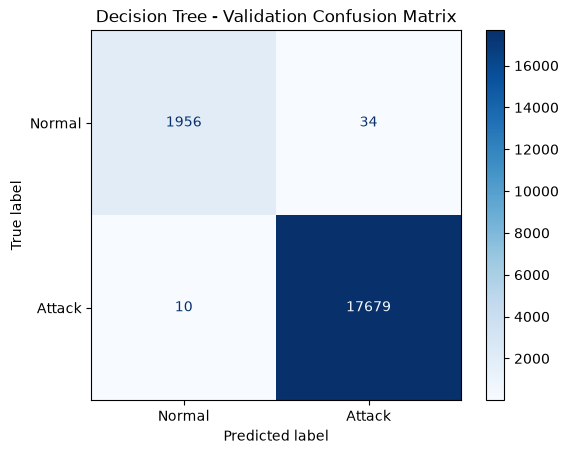

In [24]:
cm_dt = confusion_matrix(
    y_binary_val,
    y_val_pred_dt,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Normal", "Attack"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Validation Confusion Matrix")
plt.show()

In [25]:
y_train_pred_dt = decision_tree_model.predict(X_train)

train_f1_dt = f1_score(
    y_binary_train,
    y_train_pred_dt,
    pos_label=1
)

val_f1_dt = f1_score(
    y_binary_val,
    y_val_pred_dt,
    pos_label=1
)

print("Training F1:", round(train_f1_dt, 4))
print("Validation F1:", round(val_f1_dt, 4))
print("F1 difference:", round(train_f1_dt - val_f1_dt, 4))

Training F1: 1.0
Validation F1: 0.9988
F1 difference: 0.0012


In [26]:
model_results = pd.concat(
    [model_results, dt_results],
    ignore_index=True
)

display(
    model_results.sort_values(
        by="F1 Score",
        ascending=False
    )
)

model_results.to_csv(
    "../reports/metrics/binary_model_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.997764,0.991175,0.998081,0.999435,0.998757
0,Logistic Regression,0.972560,0.980945,0.999011,0.970434,0.984515


In [27]:
from sklearn.metrics import f1_score, accuracy_score

y_train_pred_dt = decision_tree_model.predict(X_train)

train_accuracy_dt = accuracy_score(
    y_binary_train,
    y_train_pred_dt
)

train_f1_dt = f1_score(
    y_binary_train,
    y_train_pred_dt,
    pos_label=1
)

val_accuracy_dt = accuracy_score(
    y_binary_val,
    y_val_pred_dt
)

val_f1_dt = f1_score(
    y_binary_val,
    y_val_pred_dt,
    pos_label=1
)

print("TRAINING PERFORMANCE")
print("Accuracy:", train_accuracy_dt)
print("F1:", train_f1_dt)

print("\nVALIDATION PERFORMANCE")
print("Accuracy:", val_accuracy_dt)
print("F1:", val_f1_dt)

print("\nF1 generalization gap:", train_f1_dt - val_f1_dt)

TRAINING PERFORMANCE
Accuracy: 1.0
F1: 1.0

VALIDATION PERFORMANCE
Accuracy: 0.9977641140301845
F1: 0.9987571323654031

F1 generalization gap: 0.0012428676345969114


In [28]:
tree = decision_tree_model.named_steps["classifier"]

print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())
print("Number of features:", tree.n_features_in_)

Tree depth: 19
Number of leaves: 130
Number of features: 93


In [29]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor_tree),

    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [31]:
random_forest_model.fit(
    X_train,
    y_binary_train
)

print("Random Forest training completed!")

Random Forest training completed!


In [32]:
y_val_pred_rf = random_forest_model.predict(X_val)

y_val_prob_rf = random_forest_model.predict_proba(X_val)

In [33]:
rf_accuracy = accuracy_score(y_binary_val, y_val_pred_rf)

rf_balanced_accuracy = balanced_accuracy_score(
    y_binary_val, y_val_pred_rf
)

rf_precision = precision_score(
    y_binary_val, y_val_pred_rf,
    pos_label=1, zero_division=0
)

rf_recall = recall_score(
    y_binary_val, y_val_pred_rf,
    pos_label=1, zero_division=0
)

rf_f1 = f1_score(
    y_binary_val, y_val_pred_rf,
    pos_label=1, zero_division=0
)

rf_results = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Balanced Accuracy": rf_balanced_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1 Score": rf_f1
}])

display(rf_results)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.997815,0.993433,0.998644,0.998926,0.998785


In [34]:
print(classification_report(
    y_binary_val,
    y_val_pred_rf,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1990
      Attack       1.00      1.00      1.00     17689

    accuracy                           1.00     19679
   macro avg       0.99      0.99      0.99     19679
weighted avg       1.00      1.00      1.00     19679



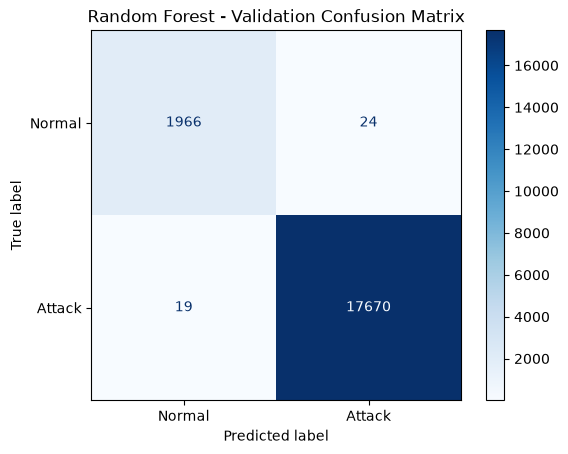

In [35]:
cm_rf = confusion_matrix(
    y_binary_val,
    y_val_pred_rf,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Normal", "Attack"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Validation Confusion Matrix")
plt.show()

In [36]:
model_results = pd.concat(
    [model_results, rf_results],
    ignore_index=True
)

display(
    model_results.sort_values(
        by="F1 Score",
        ascending=False
    )
)

model_results.to_csv(
    "../reports/metrics/binary_model_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.997815,0.993433,0.998644,0.998926,0.998785
1,Decision Tree,0.997764,0.991175,0.998081,0.999435,0.998757
0,Logistic Regression,0.972560,0.980945,0.999011,0.970434,0.984515


In [37]:
from sklearn.neighbors import KNeighborsClassifier

In [38]:
knn_model = Pipeline([
    ("preprocessor", preprocessor_scaled),

    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        metric="minkowski",
        p=2,
        n_jobs=-1
    ))
])

In [39]:
knn_model.fit(X_train, y_binary_train)

print("KNN training completed!")

KNN training completed!


In [40]:
y_val_pred_knn = knn_model.predict(X_val)

In [41]:
knn_accuracy = accuracy_score(
    y_binary_val, y_val_pred_knn
)

knn_balanced_accuracy = balanced_accuracy_score(
    y_binary_val, y_val_pred_knn
)

knn_precision = precision_score(
    y_binary_val, y_val_pred_knn,
    pos_label=1, zero_division=0
)

knn_recall = recall_score(
    y_binary_val, y_val_pred_knn,
    pos_label=1, zero_division=0
)

knn_f1 = f1_score(
    y_binary_val, y_val_pred_knn,
    pos_label=1, zero_division=0
)

knn_results = pd.DataFrame([{
    "Model": "KNN",
    "Accuracy": knn_accuracy,
    "Balanced Accuracy": knn_balanced_accuracy,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1 Score": knn_f1
}])

display(knn_results)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,KNN,0.997612,0.992874,0.998531,0.998813,0.998672


In [42]:
print(classification_report(
    y_binary_val,
    y_val_pred_knn,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1990
      Attack       1.00      1.00      1.00     17689

    accuracy                           1.00     19679
   macro avg       0.99      0.99      0.99     19679
weighted avg       1.00      1.00      1.00     19679



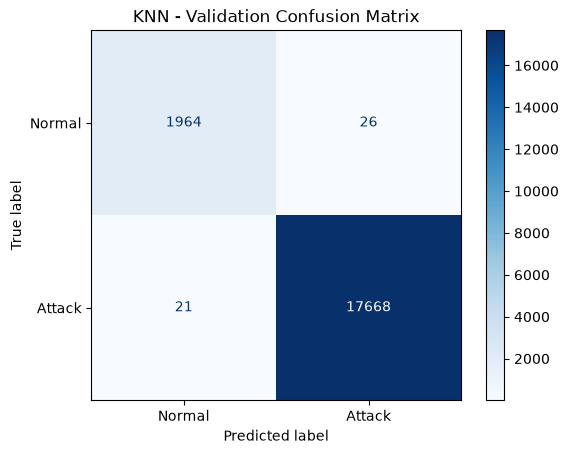

In [43]:
cm_knn = confusion_matrix(
    y_binary_val,
    y_val_pred_knn,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Normal", "Attack"]
).plot(cmap="Blues", values_format="d")

plt.title("KNN - Validation Confusion Matrix")
plt.show()

In [44]:
model_results = pd.concat(
    [model_results, knn_results],
    ignore_index=True
)

display(
    model_results.sort_values(
        by="F1 Score",
        ascending=False
    )
)

model_results.to_csv(
    "../reports/metrics/binary_model_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.997815,0.993433,0.998644,0.998926,0.998785
1,Decision Tree,0.997764,0.991175,0.998081,0.999435,0.998757
3,KNN,0.997612,0.992874,0.998531,0.998813,0.998672
0,Logistic Regression,0.972560,0.980945,0.999011,0.970434,0.984515


In [45]:
from sklearn.naive_bayes import GaussianNB

In [46]:
nb_model = Pipeline([
    ("preprocessor", preprocessor_scaled),

    ("classifier", GaussianNB())
])

In [47]:
nb_model.fit(
    X_train,
    y_binary_train
)

print("Gaussian Naive Bayes training completed!")

Gaussian Naive Bayes training completed!


In [48]:
y_val_pred_nb = nb_model.predict(X_val)

In [49]:
nb_accuracy = accuracy_score(
    y_binary_val, y_val_pred_nb
)

nb_balanced_accuracy = balanced_accuracy_score(
    y_binary_val, y_val_pred_nb
)

nb_precision = precision_score(
    y_binary_val, y_val_pred_nb,
    pos_label=1, zero_division=0
)

nb_recall = recall_score(
    y_binary_val, y_val_pred_nb,
    pos_label=1, zero_division=0
)

nb_f1 = f1_score(
    y_binary_val, y_val_pred_nb,
    pos_label=1, zero_division=0
)

nb_results = pd.DataFrame([{
    "Model": "Gaussian Naive Bayes",
    "Accuracy": nb_accuracy,
    "Balanced Accuracy": nb_balanced_accuracy,
    "Precision": nb_precision,
    "Recall": nb_recall,
    "F1 Score": nb_f1
}])

display(nb_results)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Gaussian Naive Bayes,0.942883,0.843131,0.968282,0.968172,0.968227


In [50]:
print(classification_report(
    y_binary_val,
    y_val_pred_nb,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.72      0.72      0.72      1990
      Attack       0.97      0.97      0.97     17689

    accuracy                           0.94     19679
   macro avg       0.84      0.84      0.84     19679
weighted avg       0.94      0.94      0.94     19679



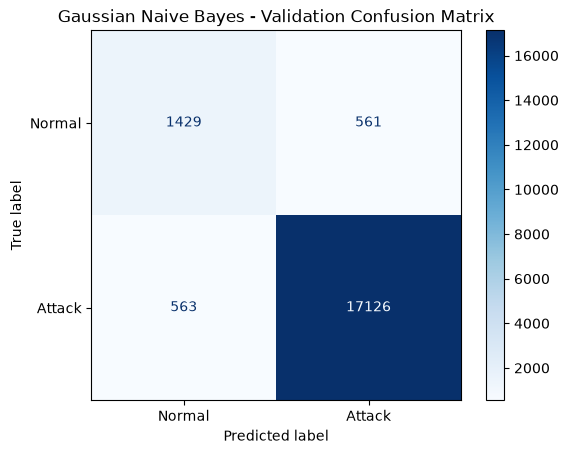

In [51]:
cm_nb = confusion_matrix(
    y_binary_val,
    y_val_pred_nb,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Normal", "Attack"]
).plot(cmap="Blues", values_format="d")

plt.title("Gaussian Naive Bayes - Validation Confusion Matrix")
plt.show()

In [52]:
model_results = pd.concat(
    [model_results, nb_results],
    ignore_index=True
)

display(
    model_results.sort_values(
        by="F1 Score",
        ascending=False
    )
)

model_results.to_csv(
    "../reports/metrics/binary_model_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.997815,0.993433,0.998644,0.998926,0.998785
1,Decision Tree,0.997764,0.991175,0.998081,0.999435,0.998757
3,KNN,0.997612,0.992874,0.998531,0.998813,0.998672
0,Logistic Regression,0.972560,0.980945,0.999011,0.970434,0.984515
4,Gaussian Naive Bayes,0.942883,0.843131,0.968282,0.968172,0.968227


In [53]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

In [54]:
X_svm_train, _, y_svm_train, _ = train_test_split(
    X_train,
    y_binary_train,
    train_size=0.25,
    stratify=y_binary_train,
    random_state=42
)

print("SVM training sample:", X_svm_train.shape)
print("SVM training labels:")
print(y_svm_train.value_counts())

SVM training sample: (19678, 82)
SVM training labels:
Binary_target
1    17690
0     1988
Name: count, dtype: int64


In [55]:
svm_model = Pipeline([
    ("preprocessor", preprocessor_scaled),

    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=42
    ))
])

In [56]:
svm_model.fit(
    X_svm_train,
    y_svm_train
)

print("SVM training completed!")

SVM training completed!


In [57]:
y_val_pred_svm = svm_model.predict(X_val)

In [58]:
svm_accuracy = accuracy_score(
    y_binary_val, y_val_pred_svm
)

svm_balanced_accuracy = balanced_accuracy_score(
    y_binary_val, y_val_pred_svm
)

svm_precision = precision_score(
    y_binary_val,
    y_val_pred_svm,
    pos_label=1,
    zero_division=0
)

svm_recall = recall_score(
    y_binary_val,
    y_val_pred_svm,
    pos_label=1,
    zero_division=0
)

svm_f1 = f1_score(
    y_binary_val,
    y_val_pred_svm,
    pos_label=1,
    zero_division=0
)

svm_results = pd.DataFrame([{
    "Model": "SVM (RBF)",
    "Accuracy": svm_accuracy,
    "Balanced Accuracy": svm_balanced_accuracy,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1 Score": svm_f1
}])

display(svm_results)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,SVM (RBF),0.976625,0.979193,0.997977,0.975974,0.986853


In [59]:
print(classification_report(
    y_binary_val,
    y_val_pred_svm,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.82      0.98      0.89      1990
      Attack       1.00      0.98      0.99     17689

    accuracy                           0.98     19679
   macro avg       0.91      0.98      0.94     19679
weighted avg       0.98      0.98      0.98     19679



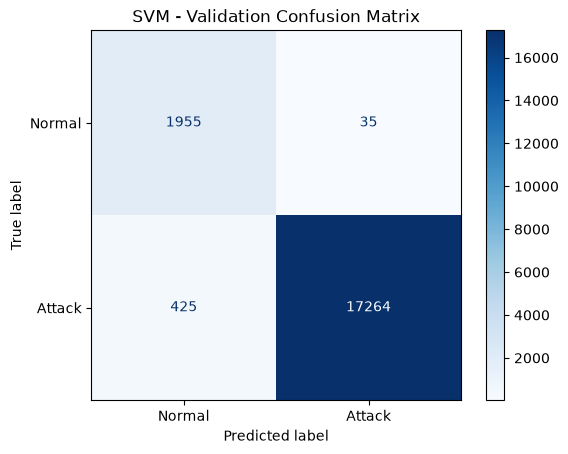

In [60]:
cm_svm = confusion_matrix(
    y_binary_val,
    y_val_pred_svm,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Normal", "Attack"]
).plot(cmap="Blues", values_format="d")

plt.title("SVM - Validation Confusion Matrix")
plt.show()

In [61]:
model_results = pd.concat(
    [model_results, svm_results],
    ignore_index=True
)

display(
    model_results.sort_values(
        by="F1 Score",
        ascending=False
    )
)

model_results.to_csv(
    "../reports/metrics/binary_model_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.997815,0.993433,0.998644,0.998926,0.998785
1,Decision Tree,0.997764,0.991175,0.998081,0.999435,0.998757
3,KNN,0.997612,0.992874,0.998531,0.998813,0.998672
5,SVM (RBF),0.976625,0.979193,0.997977,0.975974,0.986853
0,Logistic Regression,0.972560,0.980945,0.999011,0.970434,0.984515
4,Gaussian Naive Bayes,0.942883,0.843131,0.968282,0.968172,0.968227


In [62]:
from xgboost import XGBClassifier

In [63]:
negative_count = (y_binary_train == 0).sum()
positive_count = (y_binary_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Normal observations:", negative_count)
print("Attack observations:", positive_count)
print("Scale positive weight:", scale_pos_weight)

Normal observations: 7953
Attack observations: 70759
Scale positive weight: 0.11239559631990277


In [64]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor_tree),

    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    ))
])

In [65]:
xgb_model.fit(
    X_train,
    y_binary_train
)

print("XGBoost training completed!")

XGBoost training completed!


In [66]:
y_val_pred_xgb = xgb_model.predict(X_val)

In [67]:
xgb_accuracy = accuracy_score(
    y_binary_val, y_val_pred_xgb
)

xgb_balanced_accuracy = balanced_accuracy_score(
    y_binary_val, y_val_pred_xgb
)

xgb_precision = precision_score(
    y_binary_val,
    y_val_pred_xgb,
    pos_label=1,
    zero_division=0
)

xgb_recall = recall_score(
    y_binary_val,
    y_val_pred_xgb,
    pos_label=1,
    zero_division=0
)

xgb_f1 = f1_score(
    y_binary_val,
    y_val_pred_xgb,
    pos_label=1,
    zero_division=0
)

xgb_results = pd.DataFrame([{
    "Model": "XGBoost",
    "Accuracy": xgb_accuracy,
    "Balanced Accuracy": xgb_balanced_accuracy,
    "Precision": xgb_precision,
    "Recall": xgb_recall,
    "F1 Score": xgb_f1
}])

display(xgb_results)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.997917,0.997503,0.99966,0.998021,0.99884


In [68]:
print(classification_report(
    y_binary_val,
    y_val_pred_xgb,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99      1990
      Attack       1.00      1.00      1.00     17689

    accuracy                           1.00     19679
   macro avg       0.99      1.00      0.99     19679
weighted avg       1.00      1.00      1.00     19679



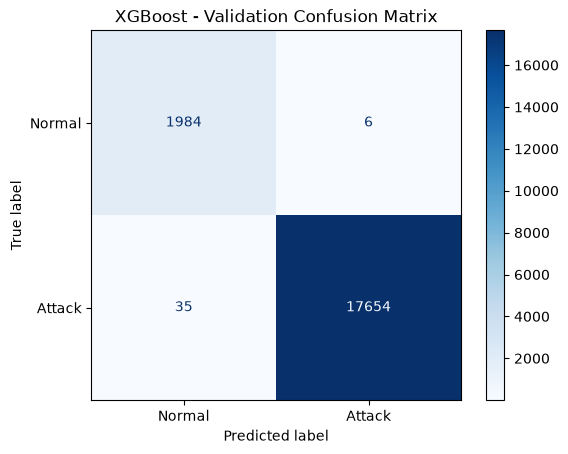

In [69]:
cm_xgb = confusion_matrix(
    y_binary_val,
    y_val_pred_xgb,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Normal", "Attack"]
).plot(cmap="Blues", values_format="d")

plt.title("XGBoost - Validation Confusion Matrix")
plt.show()

In [70]:
model_results = pd.concat(
    [model_results, xgb_results],
    ignore_index=True
)

display(
    model_results.sort_values(
        by="F1 Score",
        ascending=False
    )
)

model_results.to_csv(
    "../reports/metrics/binary_model_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
6,XGBoost,0.997917,0.997503,0.999660,0.998021,0.998840
2,Random Forest,0.997815,0.993433,0.998644,0.998926,0.998785
1,Decision Tree,0.997764,0.991175,0.998081,0.999435,0.998757
3,KNN,0.997612,0.992874,0.998531,0.998813,0.998672
5,SVM (RBF),0.976625,0.979193,0.997977,0.975974,0.986853
0,Logistic Regression,0.972560,0.980945,0.999011,0.970434,0.984515
4,Gaussian Naive Bayes,0.942883,0.843131,0.968282,0.968172,0.968227


In [71]:
import pandas as pd
import numpy as np

from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedGroupKFold
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, balanced_accuracy_score

from xgboost import XGBClassifier

In [72]:
# Identical feature rows receive the same group ID
train_groups = pd.util.hash_pandas_object(
    X_train,
    index=False
).to_numpy()

print("Training samples:", len(X_train))
print("Unique feature groups:", len(np.unique(train_groups)))

Training samples: 78712
Unique feature groups: 75467


In [73]:
# Attack is the positive class (1)
negative_count = (y_binary_train == 0).sum()
positive_count = (y_binary_train == 1).sum()

scale_pos_weight = negative_count / positive_count

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1,
        scale_pos_weight=scale_pos_weight
    ))
])

In [74]:
param_distributions = {
    "model__n_estimators": randint(150, 501),
    "model__max_depth": randint(3, 9),
    "model__learning_rate": loguniform(0.02, 0.2),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.7, 0.3),
    "model__min_child_weight": randint(1, 8),
    "model__gamma": uniform(0, 2),
    "model__reg_lambda": loguniform(0.1, 10)
}

In [75]:
cv_strategy = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="balanced_accuracy",
    cv=cv_strategy,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

xgb_search.fit(
    X_train,
    y_binary_train,
    groups=train_groups
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': <scipy.stats....002A7866907D0>, 'model__gamma': <scipy.stats....002A7811EB100>, 'model__learning_rate': <scipy.stats....002A781101D30>, 'model__max_depth': <scipy.stats....002A786690050>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",8
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computi

In [76]:
print("Best Cross-Validation Balanced Accuracy:")
print(xgb_search.best_score_)

print("\nBest Hyperparameters:")
print(xgb_search.best_params_)

best_xgb_model = xgb_search.best_estimator_

Best Cross-Validation Balanced Accuracy:
0.9963707406367321

Best Hyperparameters:
{'model__colsample_bytree': np.float64(0.7637017332034828), 'model__gamma': np.float64(0.36364993441420124), 'model__learning_rate': np.float64(0.03050945891610522), 'model__max_depth': 6, 'model__min_child_weight': 2, 'model__n_estimators': 171, 'model__reg_lambda': np.float64(0.10330768043240408), 'model__subsample': np.float64(0.7069187275124247)}


In [77]:
xgb_cv_results = pd.DataFrame(xgb_search.cv_results_)

xgb_cv_results = xgb_cv_results.sort_values(
    by="rank_test_score"
)

xgb_cv_results.to_csv(
    "../reports/metrics/xgboost_random_search.csv",
    index=False
)

print("Search results saved.")

Search results saved.


In [78]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predictions
y_val_pred_tuned = best_xgb_model.predict(X_val)

# Metrics
tuned_xgb_metrics = {
    "Model": "Tuned XGBoost",
    "Accuracy": accuracy_score(y_binary_val, y_val_pred_tuned),
    "Balanced Accuracy": balanced_accuracy_score(
        y_binary_val, y_val_pred_tuned
    ),
    "Precision": precision_score(
        y_binary_val, y_val_pred_tuned
    ),
    "Recall": recall_score(
        y_binary_val, y_val_pred_tuned
    ),
    "F1 Score": f1_score(
        y_binary_val, y_val_pred_tuned
    )
}

print(pd.Series(tuned_xgb_metrics))

print("\nConfusion Matrix:")
print(confusion_matrix(y_binary_val, y_val_pred_tuned))

print("\nClassification Report:")
print(classification_report(
    y_binary_val,
    y_val_pred_tuned,
    target_names=["Normal", "Attack"]
))

Model                Tuned XGBoost
Accuracy                    0.9969
Balanced Accuracy         0.996715
Precision                 0.999603
Recall                    0.996947
F1 Score                  0.998273
dtype: object

Confusion Matrix:
[[ 1983     7]
 [   54 17635]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      1.00      0.98      1990
      Attack       1.00      1.00      1.00     17689

    accuracy                           1.00     19679
   macro avg       0.99      1.00      0.99     19679
weighted avg       1.00      1.00      1.00     19679



In [79]:
comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "Accuracy": 0.997917,
        "Balanced Accuracy": 0.997503,
        "Precision": 0.999660,
        "Recall": 0.998021,
        "F1 Score": 0.998840
    },
    tuned_xgb_metrics
])

display(comparison.round(6))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Original XGBoost,0.997917,0.997503,0.999660,0.998021,0.998840
1,Tuned XGBoost,0.996900,0.996715,0.999603,0.996947,0.998273


In [81]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [82]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ))
])

In [83]:
rf_param_distributions = {
    "model__n_estimators": randint(100, 501),
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": randint(2, 15),
    "model__min_samples_leaf": randint(1, 8),
    "model__max_features": ["sqrt", "log2", 0.5, 0.75],
    "model__class_weight": ["balanced", "balanced_subsample"]
}

In [84]:
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=8,
    scoring="balanced_accuracy",
    cv=cv_strategy,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

rf_search.fit(
    X_train,
    y_binary_train,
    groups=train_groups
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': ['balanced', 'balanced_subsample'], 'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': <scipy.stats....002A7864F5130>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",8
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on

In [85]:
print("Best Cross-Validation Balanced Accuracy:")
print(rf_search.best_score_)

print("\nBest Hyperparameters:")
print(rf_search.best_params_)

best_rf_model = rf_search.best_estimator_

Best Cross-Validation Balanced Accuracy:
0.9971346194361397

Best Hyperparameters:
{'model__class_weight': 'balanced', 'model__max_depth': 25, 'model__max_features': 0.5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 4, 'model__n_estimators': 314}


In [86]:
rf_cv_results = pd.DataFrame(rf_search.cv_results_)

rf_cv_results = rf_cv_results.sort_values(
    by="rank_test_score"
)

rf_cv_results.to_csv(
    "../reports/metrics/random_forest_random_search.csv",
    index=False
)

print("Random Forest search results saved.")

Random Forest search results saved.


In [87]:
y_val_pred_rf_tuned = best_rf_model.predict(X_val)

tuned_rf_metrics = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(
        y_binary_val, y_val_pred_rf_tuned
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_binary_val, y_val_pred_rf_tuned
    ),
    "Precision": precision_score(
        y_binary_val, y_val_pred_rf_tuned
    ),
    "Recall": recall_score(
        y_binary_val, y_val_pred_rf_tuned
    ),
    "F1 Score": f1_score(
        y_binary_val, y_val_pred_rf_tuned
    )
}

print(pd.Series(tuned_rf_metrics))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_binary_val,
    y_val_pred_rf_tuned
))

print("\nClassification Report:")
print(classification_report(
    y_binary_val,
    y_val_pred_rf_tuned,
    target_names=["Normal", "Attack"]
))

Model                Tuned Random Forest
Accuracy                        0.998374
Balanced Accuracy               0.997981
Precision                       0.999717
Recall                          0.998474
F1 Score                        0.999095
dtype: object

Confusion Matrix:
[[ 1985     5]
 [   27 17662]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1990
      Attack       1.00      1.00      1.00     17689

    accuracy                           1.00     19679
   macro avg       0.99      1.00      1.00     19679
weighted avg       1.00      1.00      1.00     19679



In [88]:
# Get transformed feature names from the fitted preprocessor
feature_names = (
    best_rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract Random Forest importance
rf_importances = (
    best_rf_model
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(20))

,Feature,Importance
0,numerical__flow_iat.min,0.509847
1,numerical__flow_iat.avg,0.181157
2,numerical__active.min,0.131293
3,numerical__flow_iat.max,0.061856
4,numerical__flow_iat.tot,0.023963
5,numerical__active.avg,0.023403
6,numerical__flow_duration,0.020727
7,numerical__active.max,0.006014
8,numerical__flow_pkts_payload.min,0.005875
9,numerical__fwd_pkts_per_sec,0.004535


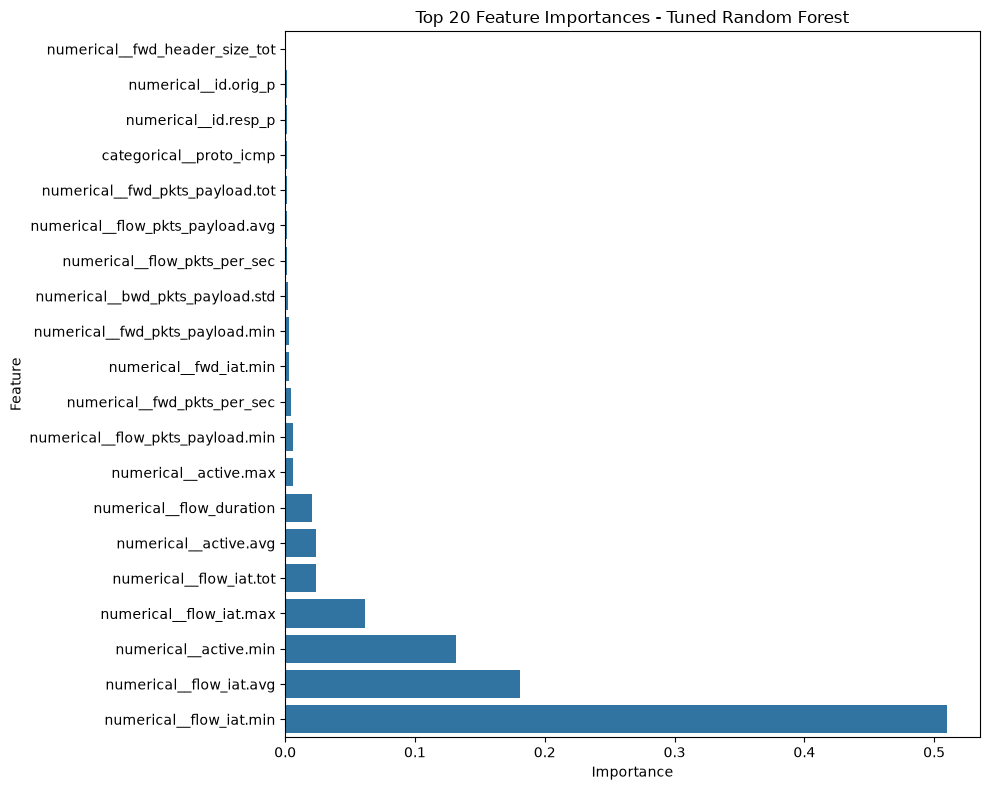

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

top_20 = importance_df.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_20,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [90]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Features to remove for this experiment
features_to_remove = [
    "proto",
    "service",
    "id.resp_p",
    "id.orig_p"
]

# Create reduced datasets
X_train_reduced = X_train.drop(
    columns=features_to_remove
)

X_val_reduced = X_val.drop(
    columns=features_to_remove
)

# Identify remaining feature types
reduced_numerical_features = [
    col for col in numerical_features
    if col not in features_to_remove
]

reduced_categorical_features = [
    col for col in categorical_features
    if col not in features_to_remove
]

print("Original features:", X_train.shape[1])
print("Reduced features:", X_train_reduced.shape[1])
print("Remaining numerical:", len(reduced_numerical_features))
print("Remaining categorical:", len(reduced_categorical_features))

Original features: 82
Reduced features: 78
Remaining numerical: 78
Remaining categorical: 0


In [91]:
preprocessor_reduced = ColumnTransformer(
    transformers=[
        (
            "numerical",
            SimpleImputer(strategy="median"),
            reduced_numerical_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="most_frequent"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            reduced_categorical_features
        )
    ]
)

In [92]:
rf_reduced_model = clone(best_rf_model)

rf_reduced_model.set_params(
    preprocessor=preprocessor_reduced
)

rf_reduced_model.fit(
    X_train_reduced,
    y_binary_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](78,)","['flow_duration','fwd_pkts_tot','bwd_pkts_tot',...,'fwd_init_window_size', 'bwd_init_window_size','fwd_last_window_size']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,78
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defaul

In [93]:
y_val_pred_reduced = rf_reduced_model.predict(
    X_val_reduced
)

reduced_metrics = {
    "Model": "Random Forest - Without Ports/Protocol/Service",
    "Accuracy": accuracy_score(
        y_binary_val, y_val_pred_reduced
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_binary_val, y_val_pred_reduced
    ),
    "Precision": precision_score(
        y_binary_val, y_val_pred_reduced
    ),
    "Recall": recall_score(
        y_binary_val, y_val_pred_reduced
    ),
    "F1 Score": f1_score(
        y_binary_val, y_val_pred_reduced
    )
}

print(pd.Series(reduced_metrics))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_binary_val,
    y_val_pred_reduced
))

Model                Random Forest - Without Ports/Protocol/Service
Accuracy                                                   0.996951
Balanced Accuracy                                          0.992729
Precision                                                  0.998586
Recall                                                     0.998021
F1 Score                                                   0.998304
dtype: object

Confusion Matrix:
[[ 1965    25]
 [   35 17654]]


In [94]:
full_model_metrics = {
    "Model": "Random Forest - All Features",
    "Accuracy": accuracy_score(
        y_binary_val,
        best_rf_model.predict(X_val)
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_binary_val,
        best_rf_model.predict(X_val)
    ),
    "Precision": precision_score(
        y_binary_val,
        best_rf_model.predict(X_val)
    ),
    "Recall": recall_score(
        y_binary_val,
        best_rf_model.predict(X_val)
    ),
    "F1 Score": f1_score(
        y_binary_val,
        best_rf_model.predict(X_val)
    )
}

ablation_comparison = pd.DataFrame([
    full_model_metrics,
    reduced_metrics
])

display(ablation_comparison.round(6))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Random Forest - All Features,0.998374,0.997981,0.999717,0.998474,0.999095
1,Random Forest - Without Ports/Protocol/Service,0.996951,0.992729,0.998586,0.998021,0.998304


In [95]:
print("FULL MODEL")
print(classification_report(
    y_binary_val,
    best_rf_model.predict(X_val),
    target_names=["Normal", "Attack"],
    digits=6
))

print("\nREDUCED MODEL")
print(classification_report(
    y_binary_val,
    y_val_pred_reduced,
    target_names=["Normal", "Attack"],
    digits=6
))

FULL MODEL
              precision    recall  f1-score   support

      Normal   0.986581  0.997487  0.992004      1990
      Attack   0.999717  0.998474  0.999095     17689

    accuracy                       0.998374     19679
   macro avg   0.993149  0.997981  0.995549     19679
weighted avg   0.998389  0.998374  0.998378     19679


REDUCED MODEL
              precision    recall  f1-score   support

      Normal   0.982500  0.987437  0.984962      1990
      Attack   0.998586  0.998021  0.998304     17689

    accuracy                       0.996951     19679
   macro avg   0.990543  0.992729  0.991633     19679
weighted avg   0.996959  0.996951  0.996954     19679



In [96]:
print("Full model:")
print(confusion_matrix(
    y_binary_val,
    best_rf_model.predict(X_val)
))

print("\nReduced model:")
print(confusion_matrix(
    y_binary_val,
    y_val_pred_reduced
))

Full model:
[[ 1985     5]
 [   27 17662]]

Reduced model:
[[ 1965    25]
 [   35 17654]]


In [97]:
from sklearn.inspection import permutation_importance

In [98]:
perm_result = permutation_importance(
    best_rf_model,
    X_val,
    y_binary_val,
    scoring="balanced_accuracy",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(permutation_df.head(20))

,Feature,Importance_Mean,Importance_Std
0,flow_iat.min,0.440561,0.001950
1,fwd_pkts_payload.min,0.031335,0.000745
2,proto,0.005065,0.000072
3,bwd_init_window_size,0.004328,0.001394
4,id.orig_p,0.003008,0.000140
5,flow_pkts_payload.min,0.000943,0.000256
6,fwd_header_size_max,0.000379,0.000029
7,flow_iat.max,0.000322,0.000093
8,flow_pkts_payload.avg,0.000291,0.000014
9,fwd_iat.min,0.000268,0.000094


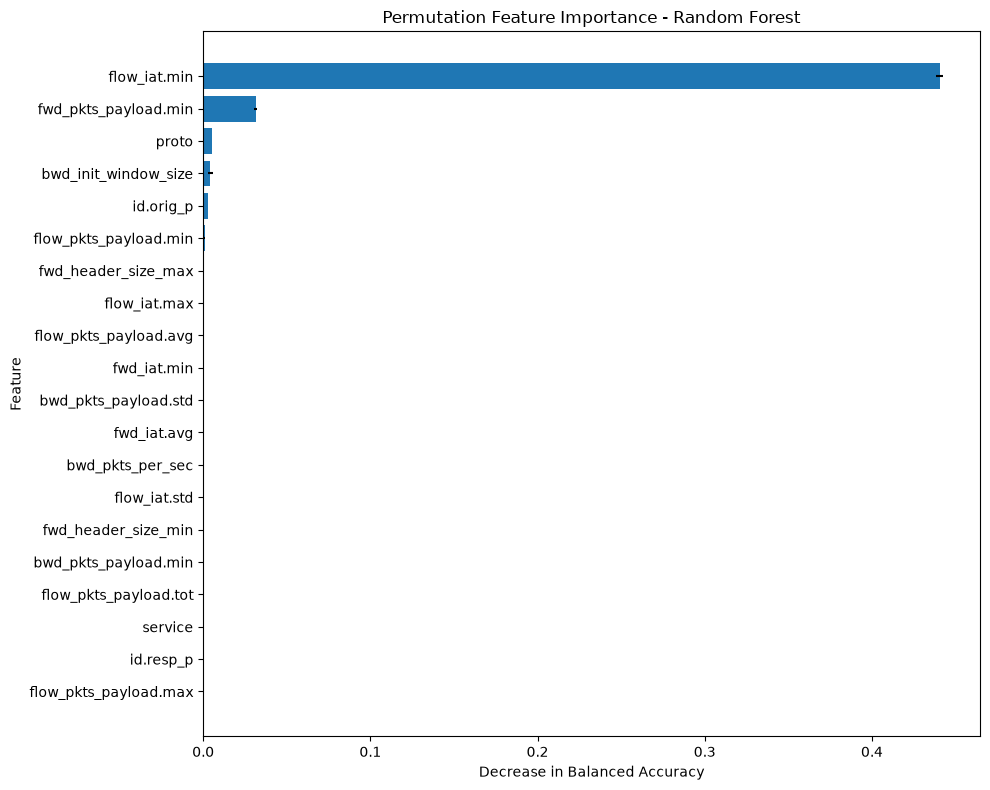

In [99]:
top_20_perm = permutation_df.head(20).sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_20_perm["Feature"],
    top_20_perm["Importance_Mean"],
    xerr=top_20_perm["Importance_Std"]
)

plt.title("Permutation Feature Importance - Random Forest")
plt.xlabel("Decrease in Balanced Accuracy")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [100]:
X_train_no_iat_min = X_train.drop(
    columns=["flow_iat.min"]
)

X_val_no_iat_min = X_val.drop(
    columns=["flow_iat.min"]
)

numerical_no_iat_min = [
    col for col in numerical_features
    if col != "flow_iat.min"
]

preprocessor_no_iat_min = ColumnTransformer(
    transformers=[
        (
            "numerical",
            SimpleImputer(strategy="median"),
            numerical_no_iat_min
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="most_frequent"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            categorical_features
        )
    ]
)

In [101]:
rf_no_iat_min = clone(best_rf_model)

rf_no_iat_min.set_params(
    preprocessor=preprocessor_no_iat_min
)

rf_no_iat_min.fit(
    X_train_no_iat_min,
    y_binary_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](81,)","['id.orig_p','id.resp_p','proto',...,'fwd_init_window_size', 'bwd_init_window_size','fwd_last_window_size']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,81
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'`

In [102]:
y_pred_no_iat_min = rf_no_iat_min.predict(
    X_val_no_iat_min
)

no_iat_min_metrics = {
    "Model": "Random Forest - Without flow_iat.min",
    "Accuracy": accuracy_score(
        y_binary_val, y_pred_no_iat_min
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_binary_val, y_pred_no_iat_min
    ),
    "Precision": precision_score(
        y_binary_val, y_pred_no_iat_min
    ),
    "Recall": recall_score(
        y_binary_val, y_pred_no_iat_min
    ),
    "F1 Score": f1_score(
        y_binary_val, y_pred_no_iat_min
    )
}

print(pd.Series(no_iat_min_metrics))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_binary_val,
    y_pred_no_iat_min
))

Model                Random Forest - Without flow_iat.min
Accuracy                                         0.998526
Balanced Accuracy                                0.998065
Precision                                        0.999717
Recall                                           0.998643
F1 Score                                          0.99918
dtype: object

Confusion Matrix:
[[ 1985     5]
 [   24 17665]]


In [103]:
dominant_feature_comparison = pd.DataFrame([
    full_model_metrics,
    reduced_metrics,
    no_iat_min_metrics
])

display(dominant_feature_comparison.round(6))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Random Forest - All Features,0.998374,0.997981,0.999717,0.998474,0.999095
1,Random Forest - Without Ports/Protocol/Service,0.996951,0.992729,0.998586,0.998021,0.998304
2,Random Forest - Without flow_iat.min,0.998526,0.998065,0.999717,0.998643,0.999180


In [104]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

test_models = {
    "Random Forest - All Features": (
        best_rf_model,
        X_test
    ),
    "Random Forest - Without flow_iat.min": (
        rf_no_iat_min,
        X_test.drop(columns=["flow_iat.min"])
    )
}

test_results = []
test_predictions = {}

for model_name, (model, X_test_input) in test_models.items():

    predictions = model.predict(X_test_input)
    test_predictions[model_name] = predictions

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_binary_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_binary_test, predictions
        ),
        "Precision": precision_score(
            y_binary_test, predictions
        ),
        "Recall": recall_score(
            y_binary_test, predictions
        ),
        "F1 Score": f1_score(
            y_binary_test, predictions
        )
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(6))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Random Forest - All Features,0.998089,0.997866,0.999728,0.998146,0.998936
1,Random Forest - Without flow_iat.min,0.997886,0.996682,0.999457,0.998191,0.998823


In [105]:
for model_name, predictions in test_predictions.items():

    print(f"\n{'='*65}")
    print(model_name)
    print("="*65)

    print(classification_report(
        y_binary_test,
        predictions,
        target_names=["Normal", "Attack"],
        digits=6
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_binary_test,
        predictions
    ))


Random Forest - All Features
              precision    recall  f1-score   support

      Normal   0.983737  0.997586  0.990613      2486
      Attack   0.999728  0.998146  0.998936     22112

    accuracy                       0.998089     24598
   macro avg   0.991732  0.997866  0.994775     24598
weighted avg   0.998112  0.998089  0.998095     24598

Confusion Matrix:
[[ 2480     6]
 [   41 22071]]

Random Forest - Without flow_iat.min
              precision    recall  f1-score   support

      Normal   0.984089  0.995173  0.989600      2486
      Attack   0.999457  0.998191  0.998823     22112

    accuracy                       0.997886     24598
   macro avg   0.991773  0.996682  0.994212     24598
weighted avg   0.997903  0.997886  0.997891     24598

Confusion Matrix:
[[ 2474    12]
 [   40 22072]]


In [106]:
test_comparison.to_csv(
    "../reports/metrics/binary_test_comparison.csv",
    index=False
)

In [107]:
final_binary_model = best_rf_model